# 02 · A whole province: Balochistan from open data

Balochistan is Pakistan's largest province by area (about 44% of the country) and its smallest by population. To
study its politics, economy and society you need data at the scale of districts, roads, borders, resources and
events. This notebook gathers them, and is honest about what they leave out.

| Layer | Source | Licence |
|---|---|---|
| Province and district boundaries | OCHA / HDX Common Operational Datasets (COD-AB, 2022) | CC BY-IGO |
| Population by district, census 2017 | HDX COD-PS, from the Pakistan Bureau of Statistics | as published by HDX |
| Roads, settlements, mines and quarries, dams, power, border crossings | OpenStreetMap, Geofabrik extract | ODbL |
| Organised violence events (in Balochistan from 1992) to 2024 | UCDP Georeferenced Event Dataset 25.1 (Uppsala) | CC BY 4.0 |

The 2023 census has published district totals too; swap them in when you need the latest figures (the method does
not change). For protests and political events after 2024, ACLED is the usual source; it needs a free account and
its terms do not allow republishing its rows, so it is shown as code you can run with your own key.

*Running this in Google Colab?* The next cell installs the few libraries Colab lacks (about a minute). Notebooks
04-07 read files made by 01 and 02: run those first in the same session, or keep the `data` folder on Google Drive.

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx", "overturemaps", "mapclassify", "esda", "libpysal", "folium", "plotly"], check=True)

In [2]:
import os, sys, re, warnings, zipfile, urllib.request
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
from pathlib import Path
if (Path(sys.prefix) / "Library/share/gdal").exists():
    os.environ["GDAL_DATA"] = str(Path(sys.prefix) / "Library/share/gdal")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA, CRS = Path("data"), 32642
get = lambda url, f: (DATA / f).exists() or urllib.request.urlretrieve(url, DATA / f)
get("https://data.humdata.org/dataset/a64d1ff2-7158-48c7-887d-6af69ce21906/resource/c6521e04-75e1-41be-8e02-0554a424d9f4/download/pak_admin_boundaries.geojson.zip", "cod_ab.geojson.zip")
get("https://data.humdata.org/dataset/9d48b019-3dd3-4284-ac11-200a70370447/resource/2fe439f1-8c17-4d5b-92d4-909858fc233b/download/pak_admpop_adm2_v2.csv", "pop_adm2.csv")
dist = gpd.read_file("zip://" + str(DATA / "cod_ab.geojson.zip") + "!pak_admin2.geojson")
dist = dist[dist.adm1_name == "Balochistan"][["adm2_name", "adm2_pcode", "area_sqkm", "geometry"]].reset_index(drop=True)
prov = dist.dissolve()
print(len(dist), "districts;", f"{dist.area_sqkm.sum():,.0f} km²")

35 districts; 346,724 km²


## Joining a table to a map, and the trap of changing codes
Census tables and boundary files share a code per district (a *P-code*). But codes and districts change: new
districts are carved out, and code systems are revised. Here the 2019 population file and the 2022 boundaries use
different codes for the same district (Awaran is PK701 in one, PK201 in the other), so we join on names, cleaned,
and list what fails to match.

In [3]:
pop = pd.read_csv(DATA / "pop_adm2.csv", encoding="utf-8-sig")
pop = pop[pop.admin1Name_en == "Balochistan"]
norm = lambda s: s.str.lower().str.replace(r"[^a-z]", "", regex=True)
dist["key"], pop["key"] = norm(dist.adm2_name), norm(pop.admin2Name_en)
pop["key"] = pop.key.replace({"sheerani": "sherani"})          # same district, two spellings (found by the check below)
dist = dist.merge(pop[["key", "T_TL", "U_TL", "R_TL", "M_TL", "F_TL"]].rename(columns={"T_TL": "pop2017", "U_TL": "urban", "R_TL": "rural", "M_TL": "male", "F_TL": "female"}), on="key", how="left")
print("districts without a 2017 population:", dist.loc[dist.pop2017.isna(), "adm2_name"].tolist())
print("population rows without a 2022 district:", sorted(set(pop.key) - set(dist.key)))

districts without a 2017 population: ['Shaheed Sikandarabad', 'Duki', 'Chaman']
population rows without a 2022 district: []


One mismatch was only spelling (Sheerani / Sherani), fixed above. The rest (Duki, Chaman, Shaheed Sikandarabad)
are districts created after 2017. A careful study would either merge new districts
back into their 2017 parents, or use 2023 census figures. Stating the mismatch is part of the method.

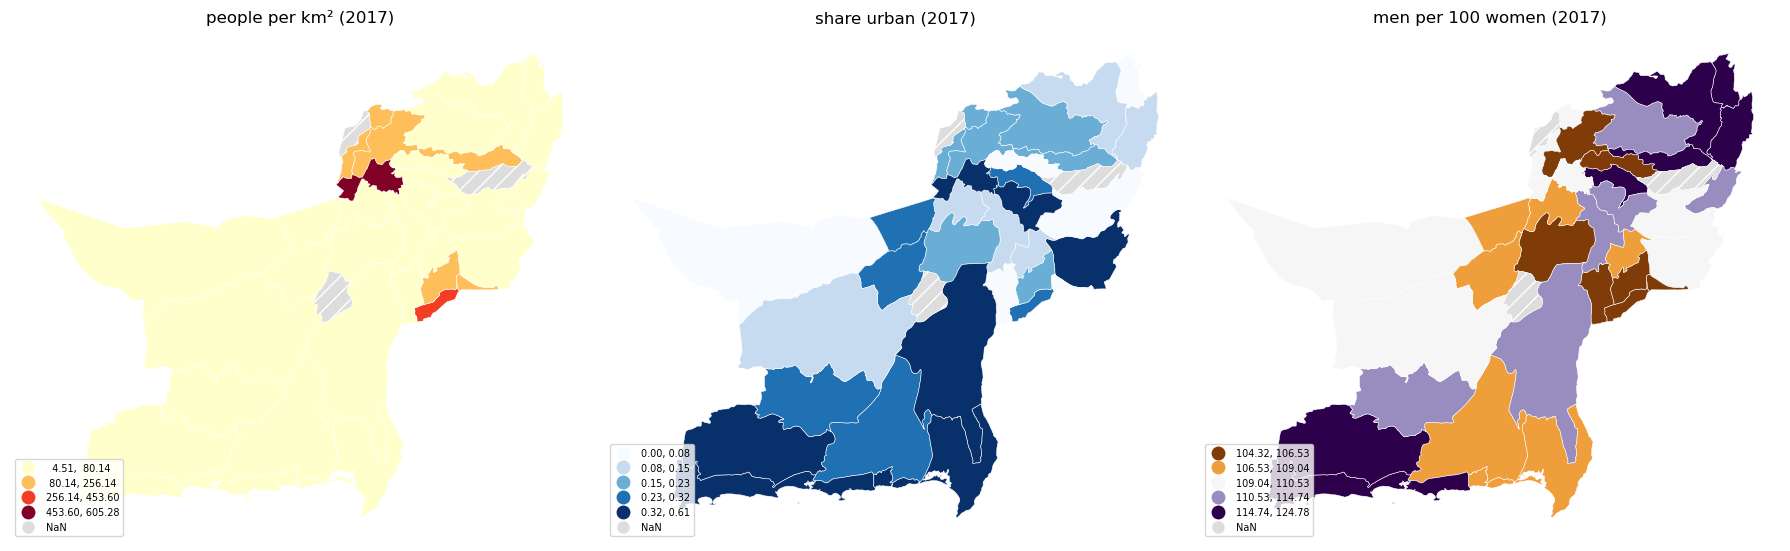

In [4]:
dist["density"] = dist.pop2017 / dist.area_sqkm
dist["urban_share"] = dist.urban / dist.pop2017
dist["sex_ratio"] = dist.male / dist.female * 100
fig, ax = plt.subplots(1, 3, figsize=(18, 7))
for a, (c, cm, t, sch) in zip(ax, [("density", "YlOrRd", "people per km² (2017)", "HeadTailBreaks"), ("urban_share", "Blues", "share urban (2017)", "Quantiles"),
                                    ("sex_ratio", "PuOr", "men per 100 women (2017)", "Quantiles")]):
    dist.plot(c, ax=a, cmap=cm, scheme=sch, k=5, legend=True, missing_kwds={"color": "#ddd", "hatch": "//"},
              legend_kwds={"loc": "lower left", "fontsize": 7, "fmt": "{:.2f}"}, edgecolor="white", lw=.4)
    a.set_title(t); a.set_axis_off()
plt.tight_layout()

In [5]:
dist[["adm2_name", "pop2017", "area_sqkm", "density", "urban_share", "sex_ratio"]].sort_values("pop2017", ascending=False).round(2).head(12)

,adm2_name,pop2017,area_sqkm,density,urban_share,sex_ratio
25,Quetta,2275699.0,3759.73,605.28,0.44,110.37
10,Kech,909116.0,24419.27,37.23,0.33,119.24
12,Khuzdar,802207.0,30954.90,25.92,0.35,110.59
13,Killa Abdullah,757578.0,2992.96,253.12,0.20,110.45
24,Pishin,736481.0,6085.88,121.01,0.19,106.09
16,Lasbela,574292.0,14057.35,40.85,0.49,108.84
6,Jaffarabad,513813.0,1701.84,301.92,0.31,104.32
21,Nasirabad,490538.0,3224.90,152.11,0.20,106.41
9,Kalat,412232.0,10179.77,40.50,0.18,105.56
18,Loralai,397400.0,3796.60,104.67,0.16,114.87


## Infrastructure and resources from OpenStreetMap
The Geofabrik extract of Pakistan (downloaded in notebook 01) holds every OSM feature. We read the province's
roads, places, mines, quarries, dams, power lines and border crossings.

In [6]:
PBF = DATA / "pakistan-latest.osm.pbf"
if not PBF.exists():
    urllib.request.urlretrieve("https://download.geofabrik.de/asia/pakistan/pakistan-latest.osm.pbf", PBF)
poly = prov.geometry.iloc[0]
def osm(layer, where):
    """Features of one layer in the province (GDAL SQL filter on the extract), with other_tags spread into columns."""
    g = gpd.read_file(PBF, layer=layer, bbox=tuple(prov.total_bounds), where=where)
    if "other_tags" in g:
        t = pd.DataFrame(list(g.other_tags.fillna("").map(lambda s: dict(re.findall(r'"([^"]+)"=>"([^"]*)"', s)))), index=g.index)
        g = pd.concat([g.drop(columns="other_tags"), t[[c for c in t.columns if c not in g.columns]]], axis=1)
    return gpd.GeoDataFrame(g, geometry="geometry", crs=4326).loc[lambda d: d.intersects(poly)]

def cached(name, make):
    """Read data/<name>.gpkg or make and save it."""
    f = DATA / f"{name}.gpkg"
    if f.exists(): return gpd.read_file(f)
    g = make(); g.to_file(f); return g

roads = cached("bal_roads", lambda: osm("lines", "highway IN ('motorway','trunk','primary','secondary')")[["name", "highway", "ref", "geometry"]])
places = cached("bal_places", lambda: osm("points", "place IN ('city','town','village')")[["name", "place", "geometry"]])
extract = cached("bal_extraction", lambda: pd.concat([
    osm("multipolygons", "landuse IN ('quarry','industrial') OR man_made IN ('mineshaft','works','petroleum_well')"),
    osm("points", "man_made IN ('mineshaft','adit','petroleum_well','works')")], ignore_index=True).assign(
        geometry=lambda d: d.geometry.representative_point())[["name", "landuse", "man_made", "geometry"]])
border = cached("bal_border", lambda: osm("points", "barrier = 'border_control'")[["name", "geometry"]])
print(f"main roads {roads.to_crs(CRS).length.sum() / 1e3:,.0f} km; towns and villages {len(places):,}; "
      f"mines, quarries, wells and works {len(extract):,}; border crossings {len(border)}")
roads.highway.value_counts()

main roads 9,438 km; towns and villages 1,545; mines, quarries, wells and works 275; border crossings 11


highway
trunk        1136
secondary     911
primary       518
Name: count, dtype: int64

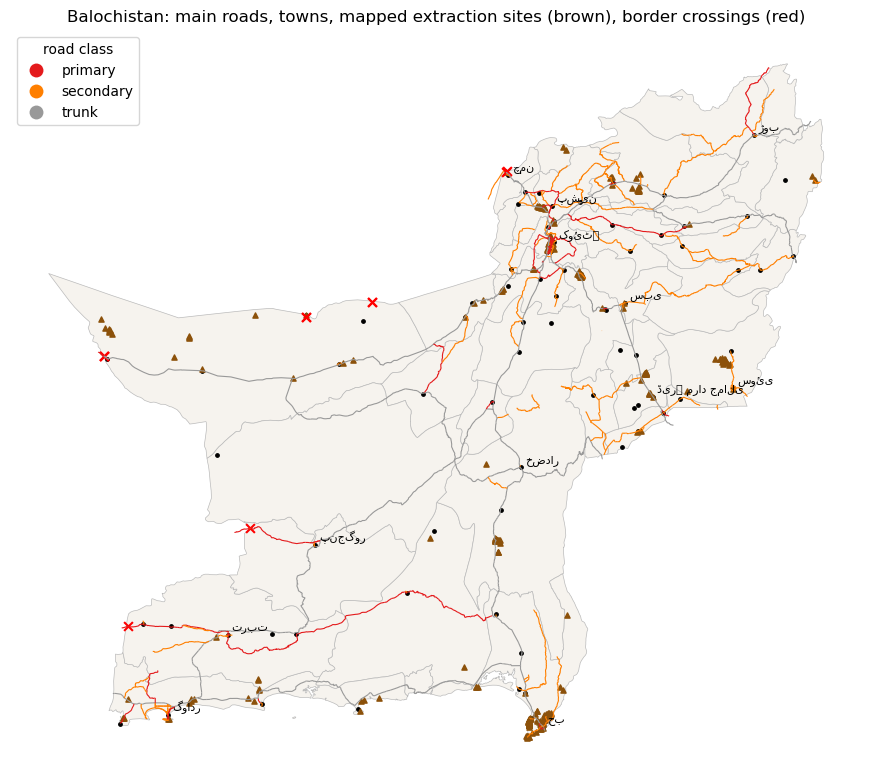

In [7]:
fig, ax = plt.subplots(figsize=(11, 11))
dist.plot(ax=ax, color="#f6f3ee", edgecolor="#bbb", lw=.5)
roads.plot(ax=ax, column="highway", categorical=True, lw=.8, legend=True, cmap="Set1", legend_kwds={"loc": "upper left", "title": "road class"})
places[places.place.isin(["city", "town"])].plot(ax=ax, color="black", markersize=6)
extract.plot(ax=ax, color="#8c510a", marker="^", markersize=14)
border.plot(ax=ax, color="red", marker="x", markersize=40)
for _, r in places[places.place == "city"].iterrows():
    ax.annotate(r["name"], (r.geometry.x, r.geometry.y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_title("Balochistan: main roads, towns, mapped extraction sites (brown), border crossings (red)"); ax.set_axis_off();

## Events through time: UCDP organised violence
UCDP records each event of organised violence with at least one death that it can verify from news and NGO
reports: who against whom, where (with a precision code), when, and best, low and high death estimates. It is a
careful, conservative source: it misses unreported events, and enforced disappearances, arrests and protests are
not in it at all.

In [8]:
ev_f = DATA / "ucdp_balochistan.csv"
if not ev_f.exists():
    z = DATA / "ged.zip"; urllib.request.urlretrieve("https://ucdp.uu.se/downloads/ged/ged251-csv.zip", z)
    g = pd.read_csv(zipfile.ZipFile(z).open(zipfile.ZipFile(z).namelist()[0]), low_memory=False)
    g[(g.country == "Pakistan") & g.adm_1.str.contains("Baluch|Baloch", na=False)].to_csv(ev_f, index=False); z.unlink()
ev = pd.read_csv(ev_f)
ev = gpd.GeoDataFrame(ev, geometry=gpd.points_from_xy(ev.longitude, ev.latitude), crs=4326)
ev["kind"] = ev.type_of_violence.map({1: "state-based", 2: "non-state", 3: "one-sided (against civilians)"})
print(len(ev), "events,", ev.year.min(), "-", ev.year.max(), "; best estimate of deaths:", int(ev.best.sum()))
print("location precision (1 = exact place ... 6+ = province or country):"); print(ev.where_prec.value_counts().sort_index())

1099 events, 1992 - 2024 ; best estimate of deaths: 4251
location precision (1 = exact place ... 6+ = province or country):
where_prec
1    415
2    374
3    267
4     28
5     15
Name: count, dtype: int64


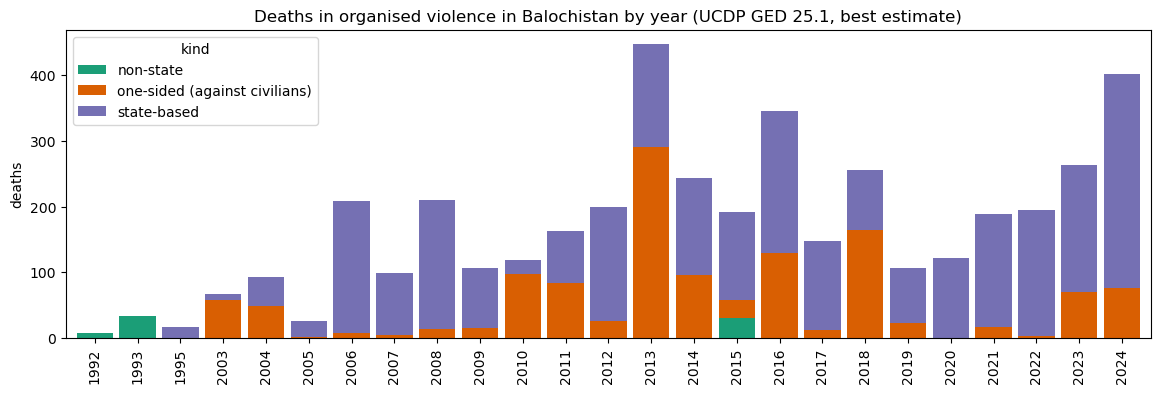

In [9]:
y = ev.groupby(["year", "kind"]).best.sum().unstack(fill_value=0)
ax = y.plot.bar(stacked=True, figsize=(14, 4), width=.85, color=["#1b9e77", "#d95f02", "#7570b3"])
ax.set(title="Deaths in organised violence in Balochistan by year (UCDP GED 25.1, best estimate)", xlabel="", ylabel="deaths");

In [10]:
ev.groupby("side_b").agg(events=("id", "size"), deaths=("best", "sum")).sort_values("events", ascending=False).head(10)

,events,deaths
side_b,,
BRAS,409,801
BLA,193,548
Civilians,151,1260
BRA,148,380
TTP,96,447
IS,32,264
BLF,17,105
UBA,14,118
Baloch Ittehad,9,157


**Reading the actors:** in state-based events side A is the Government of Pakistan and side B the armed group
(BLA, BLF, BRA, BRAS and others, as UCDP names them); one-sided violence is violence by an organised group against
civilians. These are UCDP's categories, not neutral facts: who is called what is political (notebook 07).

## Joining events to districts: rates, not dots

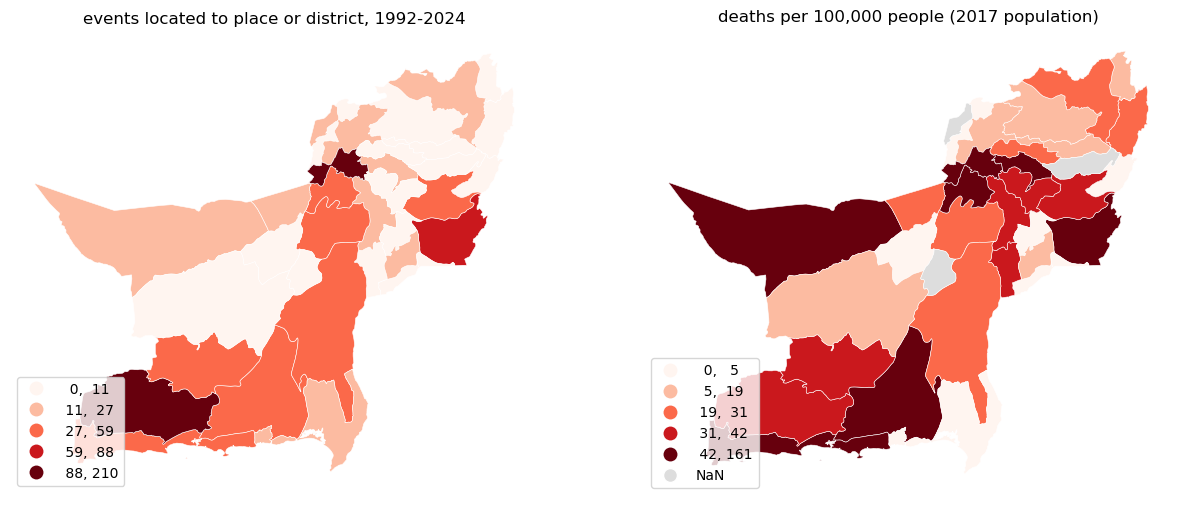

In [11]:
j = gpd.sjoin(ev[ev.where_prec <= 3], dist[["adm2_name", "geometry"]], predicate="within")
k = j.groupby("adm2_name").agg(events=("id", "size"), deaths=("best", "sum"))
dist = dist.merge(k, on="adm2_name", how="left").fillna({"events": 0, "deaths": 0})
dist["deaths_per_100k"] = dist.deaths / dist.pop2017 * 1e5
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
dist.plot("events", ax=ax[0], cmap="Reds", scheme="NaturalBreaks", k=5, legend=True, edgecolor="white", lw=.4, legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
dist.plot("deaths_per_100k", ax=ax[1], cmap="Reds", scheme="Quantiles", k=5, legend=True, edgecolor="white", lw=.4, missing_kwds={"color": "#ddd"}, legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
ax[0].set_title(f"events located to place or district, {ev.year.min()}-{ev.year.max()}"); ax[1].set_title("deaths per 100,000 people (2017 population)")
for a in ax: a.set_axis_off()

## An interactive map with a time slider
Drag the slider (or press play) to watch events appear year by year.

In [12]:
import folium
from folium.plugins import TimestampedGeoJson
m = folium.Map(location=[28.5, 65.5], zoom_start=6, tiles="Esri.WorldGrayCanvas")
folium.GeoJson(dist[["adm2_name", "pop2017", "events", "geometry"]].to_json(), name="districts",
               style_function=lambda f: {"fillOpacity": 0, "color": "#666", "weight": .6},
               tooltip=folium.GeoJsonTooltip(["adm2_name", "pop2017", "events"])).add_to(m)
col = {"state-based": "#1b9e77", "non-state": "#d95f02", "one-sided (against civilians)": "#7570b3"}
feats = [{"type": "Feature", "geometry": {"type": "Point", "coordinates": [r.longitude, r.latitude]},
          "properties": {"time": f"{int(r.year)}-01-01", "popup": f"{r.date_start[:10]}: {r.dyad_name}, {int(r.best)} deaths",
                         "icon": "circle", "iconstyle": {"color": col[r.kind], "fillColor": col[r.kind], "fillOpacity": .6, "radius": 3 + min(r.best, 30) ** .5}}}
         for r in ev[ev.where_prec <= 3].itertuples()]
TimestampedGeoJson({"type": "FeatureCollection", "features": feats}, period="P1Y", duration="P3Y", add_last_point=False,
                   auto_play=False, loop=False, date_options="YYYY", time_slider_drag_update=True).add_to(m)
m

## ACLED: protests and political events (needs your own free key)
ACLED codes protests, riots, strategic developments and violence weekly. Register at acleddata.com, then run with
your key in environment variables (never paste a key into a notebook you share). Its terms let you analyse and
publish maps and statistics, not redistribute the rows.

```python
import os, requests
r = requests.get("https://api.acleddata.com/acled/read", params={
    "key": os.environ["ACLED_KEY"], "email": os.environ["ACLED_EMAIL"],
    "country": "Pakistan", "admin1": "Balochistan", "limit": 0})
acled = pd.DataFrame(r.json()["data"])
acled.event_type.value_counts()      # Protests, Riots, Battles, Violence against civilians, ...
```

## Save for later notebooks

In [13]:
dist.drop(columns="key").to_file(DATA / "bal_districts.gpkg")
ev.to_file(DATA / "bal_events.gpkg")
print("saved")

saved


**Credits:** boundaries OCHA/HDX COD-AB (CC BY-IGO); population HDX COD-PS from the Pakistan Bureau of Statistics
census 2017; © OpenStreetMap contributors (ODbL); UCDP GED 25.1 (Sundberg and Melander 2013; Davies et al. 2025),
CC BY 4.0.